# fMRI オープンデータ解析講習：まとめ

今日の 4 つのノートブックをふりかえり、この先どう学ぶかをまとめます。

このノートブックにはコードがありません。ランタイムにつながなくても読めます。

### このノートブックの読み方

左に縦線の付いていない文がメインの文章です。左に縦線が付いた「**くわしく**」は、時間があるときや、
あとで読むための部分で、講習の間は読み飛ばしてかまいません。

## 1. 今日やったこと

| | 問い | データ | 方法 | 結果 |
|---|---|---|---|---|
| **01** | 顔条件で、脳のどこが強く反応するか | AOMIC PIOP1（1 人分） | GLM、FWE の補正 | 左の側頭葉の下の面（紡錘状回のあたり）や後頭葉などで、図形条件より強く反応した（既定の sub-0002） |
| **02** | 脳の活動のパターンから、初めて見る人が顔条件と図形条件のどちらを行っていたかを当てられるか | AOMIC PIOP1（20 人） | 線形 SVM、1 人除きの交差検証、並べ替え検定 | 正解率 0.96（偶然なら約 0.5、p = 0.001） |
| **03** | 定型の人で学習した分類器は、ASD の人の脳からも、誤信念の話か写真の話かを当てられるか | ds000212（30 人） | 線形 SVM、定型の人で学習して ASD の人で試す、並べ替え検定 | ASD の人でも、定型の人どうしと同じくらい当たった（0.77 と 0.78。偶然なら 0.5）。反応の差は、どちらの群でも側頭頭頂接合部と楔前部に出た |
| **04** | 安静時の脳のつながりから、ASD の人か定型の人かを当てられるか | ABIDE I（871 人） | 線形 SVM、10 分割の交差検証、並べ替え検定 | 正解率 約 0.69（多いほうの群を答え続けると 0.54）。偶然ではないが違いは小さく、捉えるには数百人が要った。手順を誤ると、乱数でも 0.9 以上当たった（リーク） |

01 と 02 では、同じデータを 2 つの向きから見ました。GLM は「課題でどこが反応するか」を、デコーディングは
「脳の活動のパターンから課題を当てられるか」を調べます。03 と 04 では、同じ道具を ASD の研究の問いに使いました。
03 では、課題への脳の反応の違いが ASD の人と定型の人で共通していました。04 では、脳のつながりに小さいけれども偶然ではない
違いがあり、それを捉えるには、正しい手順と多くの人数が要りました。

## 2. 今日のデータが通ってきた道と、研究で加わること

01 の 1 章の図をもう一度見ます。

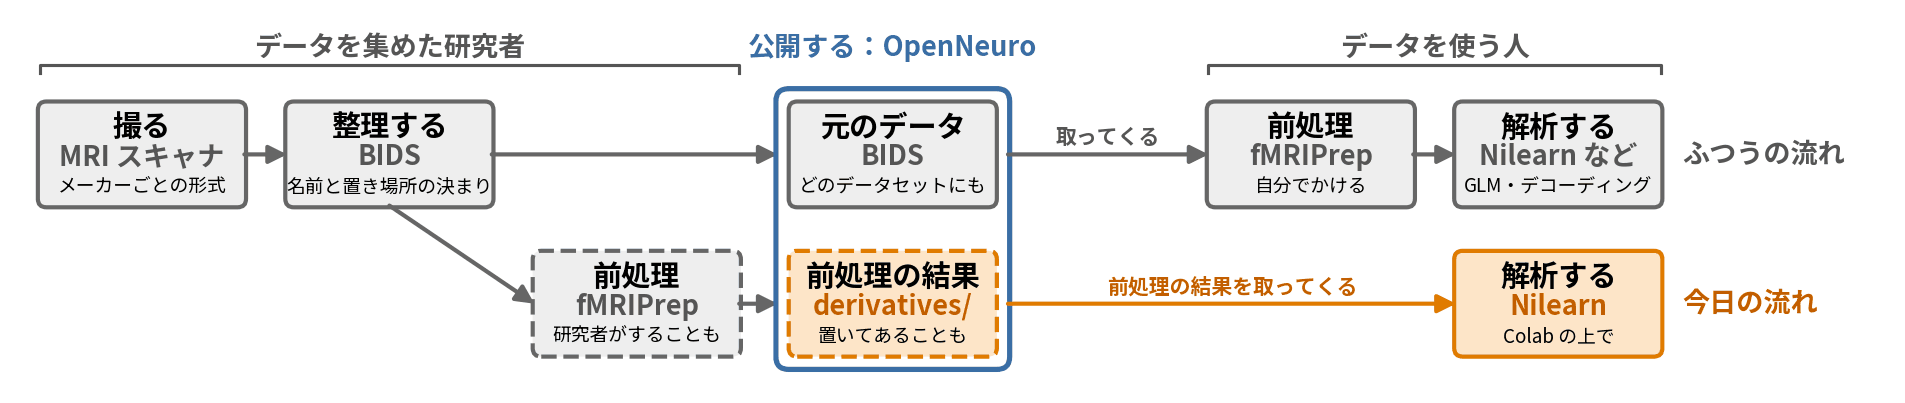

今日は 4 つとも、誰かが済ませた前処理の結果を取ってきて、そのまま解析する、下の段の形でした。
自分で研究するときは、上の段の流れになり、次のことが加わります。

- 自分で撮ったデータを **BIDS** にそろえる（dcm2niix などで変換し、決まった名前と置き場所に並べる）
- **fMRIPrep** を Docker や Apptainer のコンテナで動かし、1 人ずつ報告書（HTML）で処理の結果を目で確かめる
- 01 の 1 人ずつの解析を全員分行い、**集団の解析** で人々に共通する反応を調べる（Nilearn では `SecondLevelModel`）
- 使ったデータとソフトのバージョンを記録し、論文と一緒に、データを OpenNeuro で公開する

> **くわしく**（時間があれば）
>
> 前処理をしたのは、01・02 ではデータを集めた研究者（OpenNeuro の同じデータセットの `derivatives/`）、03 では OpenNeuro の
> 前処理のチーム（OpenNeuro Derivatives）、04 では PCP（置き場所も OpenNeuro ではありません）です。

## 3. 持ち帰りたいこと：ASD の人と定型の人を比べる研究を計画するときに

02〜04 から挙げます。脳波など、ほかの計測で比べるときにも当てはまります。

1. **特徴を選ぶ、設定を選ぶなど、データを見て決めることは、すべて交差検証の内側で**。試したことは、すべて書きます。
2. **数十人の研究の正解率は、人の選び方だけで大きくぶれる**。人数を増やすか、幅を一緒に示します。
3. **差が見つからないことは、差が無いことではない**。差がどのくらいの幅でありうるかも一緒に示します。
4. **群と、記録の条件や脳以外のものを重ねない**。施設・装置・時期が群で偏ると、その違いを当てただけで「ASD を当てた」
   ように見えます。
5. **条件の順番は、人によって入れ替える**（カウンターバランス）。
6. **当てられることは、診断に使えることとも、仕組みが分かったこととも違う**。

> **くわしく**（時間があれば）
>
> - 1 について：外で選ぶと、乱数でも 0.9 以上当たってしまいます（04 の 6 章）。何を試すかは、できればデータを見る前に
>   決めて書いておき、p 値を読むときにも、試したことを考えに入れます。
> - 2 について：04 の ASD 20 人・定型 20 人の研究では、0.4 以下〜0.7 以上にぶれました。
> - 3 について：03 では、定型 → ASD の正解率は定型どうしとほぼ同じでしたが、差の参考範囲は ±0.1 くらいに広がっていました。
> - 4 について：公開データを使うときは、解析の前に、群と施設（装置・時期）の表を作って重なりを見ます。重なりが大きいと、
>   あとの解析では切り離せません。例えば、定型の人のデータベースに、別の機会に集めた ASD の人のデータを足すときは、
>   同じ条件で撮った定型の人も足します。頭や体の動き（脳波なら瞬きや筋肉の電位）、眠気、年齢、性など、群で違いやすい
>   ものは測っておき、それだけでどのくらい当たるかを、脳の結果と並べて示します（04 の 5 章の「くわしく」）。
> - 5 について：全員が同じ順番だと、課題の違いと、時間とともにゆっくり変わるもの（眠気、慣れ、装置の状態）を、解析では
>   切り離せません（02 の 7 章）。

## 4. 今日出てきたことば

あとで読み返すときに使ってください。

| ことば | ひとことで | 説明した場所 |
|---|---|---|
| BOLD 信号 | 神経の活動のあとに血流が増えて、MRI の信号が少し上がること。fMRI が測っているもの | 01 の 1 章 |
| BIDS、NIfTI | 脳画像のファイルの名前と置き場所の決まり。脳画像のファイルの形式 | 01 の 1 章 |
| 前処理、fMRIPrep | 頭の動きのずれなどを直し、標準脳（MNI）の形にそろえる処理。それを自動でする道具 | 01 の 1 章 |
| ボクセル、TR | 画像を区切った小さな箱。画像を撮る間隔（今日は 2 秒） | 01 の 3 章 |
| 条件、試行 | 実験で比べる場面（今日は顔条件と図形条件）。その中の 1 回分の問い | 01 の 2 章 |
| ブロック、run | 同じ条件の試行が続くまとまり。1 回の撮像 | 01 の 2 章 |
| HRF、設計行列 | 神経の活動のあとの血流の反応の形。予想される反応を列に並べた表 | 01 の 6 章 |
| GLM、コントラスト、z 値 | 信号を予想される反応の重みで説明する方法。2 つの重みの差。その差が雑音の何倍か | 01 の 6・7 章 |
| 多重比較、FWE、FDR | たくさんの場所を調べると偶然の当たりが増えること。その補正の 2 つのやり方 | 01 の 7・9 章 |
| デコーディング、分類器 | 脳の活動から課題などを当てる解析。例と正解から当て方を学ぶ仕組み | 02 の冒頭 |
| 学習、テスト | 当て方を決めること。学習に使っていない例で試すこと | 02 の冒頭 |
| 線形 SVM | ボクセルごとの重みを決めて、「パターン × 重み」の合計の正負で答える分類器 | 02 の 4 章 |
| 交差検証 | テスト用の人を入れ替えながら、学習とテストを繰り返すこと | 02 の 4 章 |
| 並べ替え検定、p 値 | ラベルを入れ替えて、偶然ならどのくらい当たるかを作って比べること | 02 の 5 章 |
| カウンターバランス | 条件の順番を人によって入れ替えること | 02 の 7 章 |
| 心の理論、誤信念課題 | 人の心の中を推し量ること。それに関わる脳の領域を調べる標準的な課題 | 03 の 1 章 |
| 安静時 fMRI、機能的結合 | 何もしていないときの fMRI。領域どうしの信号の相関 | 04 の冒頭・4 章 |
| balanced accuracy | 群ごとの正解率の平均。群の人数が違うときに使う | 04 の 7.2 の「くわしく」 |
| リーク | テストする人の答えを、学習の外で見てしまうこと | 04 の 6 章 |

## 5. この先の学び方

おすすめの順番です。

1. **今日のノートブックをもう一度動かす**：上から順に実行し直し、各ノートブックの「自分で試してみよう」を解きます。
   参加者や閾値を変えて、結果がどう変わるかを見ます。教材は <https://github.com/kaosu-research/fmri-opendata-workshop> に
   あり、各ノートブックを Colab で開くリンクも、そこに並べてあります。
2. **基礎を固める**
   - DartBrains（Python で fMRI の解析を学ぶ教材）：<https://dartbrains.org/>
   - Andy's Brain Book（FSL、SPM、AFNI などの解析ソフトの使い方の解説と動画）：<https://andysbrainbook.readthedocs.io/>
   - 教科書：Poldrack, Mumford, & Nichols, *Handbook of Functional MRI Data Analysis*（Cambridge University Press, 2011）
   - Nilearn の例：<https://nilearn.github.io/stable/auto_examples/index.html>
3. **公開データで試す**：OpenNeuro（<https://openneuro.org/>）で、関心に近い課題のデータセットを探し、今日のノートブックを
   書き換えて解析してみます。
4. **自分のデータで流れを通す**：BIDS にそろえ（<https://bids.neuroimaging.io/getting_started/>）、fMRIPrep（<https://fmriprep.org/>）を
   まず 1 人分だけ動かして報告書を読み、1 人ずつの GLM から集団の解析へ進みます。
5. **脳波で同じことをする**：Python で脳波・脳磁図を解析するライブラリ MNE-Python（<https://mne.tools/>）が、今日の
   Nilearn にあたります。今日の 02〜04 で見た注意（リーク、人数など）は、脳波でも同じです。
6. **困ったら聞く**：NeuroStars（fMRIPrep や Nilearn などの質問の場。英語）：<https://neurostars.org/>
7. **再現できる解析を学ぶ**：ReproNim（<https://repronim.org/>）、DataLad（<https://www.datalad.org/>）

> **くわしく**（時間があれば）
>
> BIDS には脳波の決まり（EEG-BIDS。<https://bids-specification.readthedocs.io/en/stable/modality-specific-files/electroencephalography.html>）
> もあり、OpenNeuro には脳波のデータセットもあります。

## データと文献の出典

- 01・02 のデータ：Snoek, L., van der Miesen, M. M., Beemsterboer, T., van der Leij, A., Eigenhuis, A., & Scholte, H. S. (2021).
  The Amsterdam Open MRI Collection, a set of multimodal MRI datasets for individual difference analyses.
  *Scientific Data*, 8, 85. <https://doi.org/10.1038/s41597-021-00870-6> （OpenNeuro ds002785、CC0）
- 03 のデータ：Koster-Hale, J., Saxe, R., Dungan, J., & Young, L. L. (2013). Decoding moral judgments from neural
  representations of intentions. *PNAS*, 110, 5648–5653. <https://doi.org/10.1073/pnas.1207992110> （OpenNeuro ds000212、CC0。
  前処理済みのデータは OpenNeuro Derivatives の `ds000212-fmriprep`）
- 04 のデータ：Di Martino, A., et al. (2014). The autism brain imaging data exchange: towards a large-scale evaluation of the
  intrinsic brain architecture in autism. *Molecular Psychiatry*, 19, 659–667. <https://doi.org/10.1038/mp.2013.78>
- 04 の前処理済みのデータ：Craddock, C., et al. (2013). The Neuro Bureau Preprocessing Initiative: open sharing of
  preprocessed neuroimaging data and derivatives. *Frontiers in Neuroinformatics*, Conference Abstract: Neuroinformatics 2013.
  <https://doi.org/10.3389/conf.fninf.2013.09.00041>
- 脳波の BIDS：Pernet, C. R., et al. (2019). EEG-BIDS, an extension to the brain imaging data structure for
  electroencephalography. *Scientific Data*, 6, 103. <https://doi.org/10.1038/s41597-019-0104-8>
- 脳波の解析：Gramfort, A., et al. (2013). MEG and EEG data analysis with MNE-Python. *Frontiers in Neuroscience*, 7, 267.
  <https://doi.org/10.3389/fnins.2013.00267>
- 教科書：Poldrack, R. A., Mumford, J. A., & Nichols, T. E. (2011). *Handbook of Functional MRI Data Analysis*.
  Cambridge University Press. <https://doi.org/10.1017/CBO9780511895029>